In [11]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import numpy as np
import os

# Load Data

In [6]:
DATA_PATH = os.path.join("..","..","data")
data_set = "homogenous"
WAVE_FILE = os.path.join(DATA_PATH,"wavefields",data_set,"wavefield_00.npy") # 
wave_data = np.load(WAVE_FILE, mmap_mode='r')
print(wave_data.shape)

VEL_MOD_FILE = os.path.join(DATA_PATH, "vel_models",data_set,"model_00.npy") # londono, seismological
vel_data = np.load(VEL_MOD_FILE)
print(vel_data.shape)

SRC_FILE = os.path.join(DATA_PATH,"source_functions","ricker.npy")
src_data = np.load(SRC_FILE)
print(src_data.shape)

(7, 800, 70, 70)
(7, 1, 70, 70)
(800, 2)


# Plots

In [3]:
import matplotlib.pyplot as plt
def plot_source(t, g):
        plt.plot(t, g)
        plt.xlabel("time (s)")
        plt.ylabel("Amplitude")
        plt.grid()
        plt.show()

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def plot_source_frec(t, g):
    dt = np.mean(np.diff(t))
    N = len(t)

    # Transformada de Fourier
    G = np.fft.rfft(g)
    freq = np.fft.rfftfreq(N, d=dt)

    # Espectro de amplitud
    amplitude = np.abs(G) / N
    amplitude[1:-1] *= 2
    print(f"Frecuencia central {freq[np.argmax(amplitude)]}")
    print(f"Frecuencia máxima (-3 dB): {freq[amplitude >= np.max(amplitude) / np.sqrt(2)][-1]:.2f} Hz")

    plt.figure(figsize=(8, 4))
    plt.plot(freq, amplitude)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.show()

In [ ]:
from src.myplotters import plot_velmodel, plot_x_z_t_slices, plot_traces_vertical #, plot_changes, plot_t_slice, plot_traces_vertical

In [ ]:
n = 0
vel_n = vel_data[n,0]
wave_n = wave_data[n]
t = 200
z = 0
x = 35


### Source

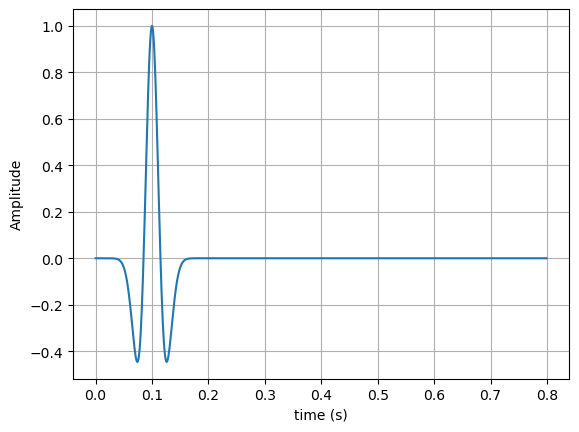

Frecuencia central 15.0
Frecuencia máxima (-3 dB): 21.25 Hz


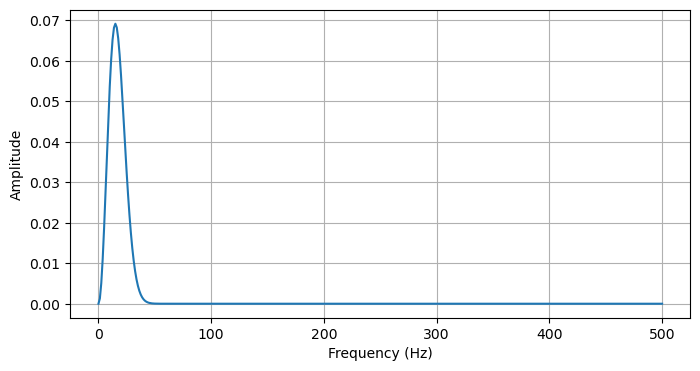

In [15]:
plot_source(src_data[:,0], src_data[:,1])
plot_source_frec(src_data[:,0], src_data[:,1])

### Velocity Model

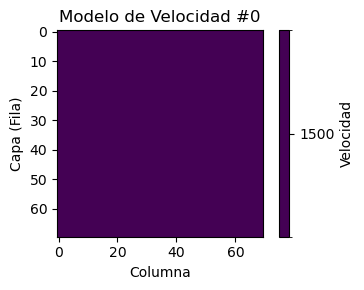

In [ ]:
plot_velmodel(vel_n, n=n)

### Wavefield

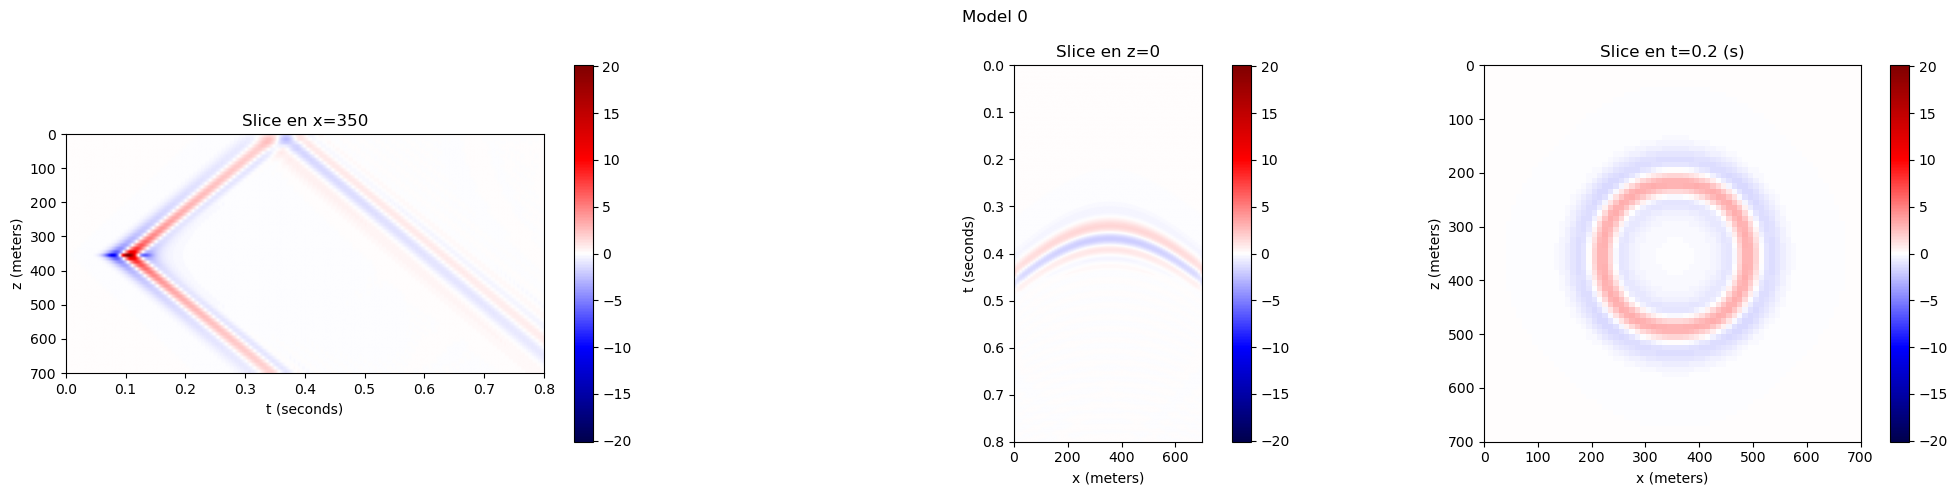

In [ ]:
plot_x_z_t_slices(wave_n, x,z, t, delta_h=10, delta_t=0.001, Title=f"Model {n}")

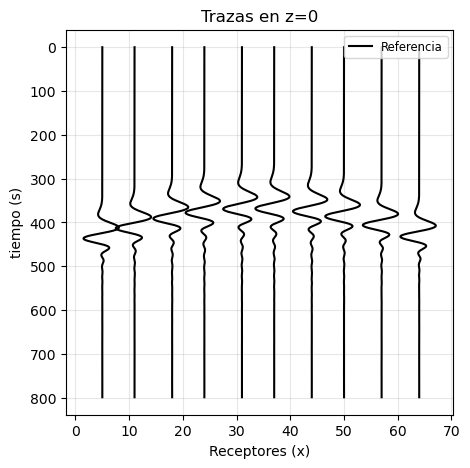

In [ ]:
plot_traces_vertical(wave_n, z_index=z)